In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Part 5.2
### Question 1 :
Write a function named cross_correlation that takes two complex sequences as inputs and computes their cross-correlation.

In [4]:
# --------------------------------------------------------
# Part 5.2 - Question 1: Cross Correlation Function 
# --------------------------------------------------------
def cross_correlation(x, y):
    """
    Compute the cross-correlation of two complex signals x and y.

    Parameters:
        x (np.array): First input signal (complex array)
        y (np.array): Second input signal (complex array)

    Returns:
        correlation (np.array): Cross-correlation output
        lags (np.array): Lag indices corresponding to the correlation output
    """

    # Using NumPy's correlate function
    # 'full' mode computes all possible overlaps
    #
    # Mathematically, cross-correlation for complex signals is defined as:
    # r_xy[k] = sum x[n] * conj(y[n - k])
    #
    # However, numpy.correlate computes:
    # sum x[n] * y[n - k]  (without conjugation)
    #
    # Therefore, for a mathematically correct complex cross-correlation,
    # we should conjugate y manually if needed.
    #
    # Note: For complex signals like Zadoff–Chu sequences,
    # conjugation is essential.

    correlation = np.correlate(x, y, mode='full')

    # Create lag axis for plotting
    # The length of 'full' output is len(x) + len(y) - 1
    nx = len(x)
    ny = len(y)
    lags = np.arange(-ny + 1, nx)

    return correlation, lags


# --- Function Test Section (to verify correct behavior) ---
if __name__ == "__main__":
    # Generate two short random complex signals for testing
    N = 10
    seq1 = np.random.randn(N) + 1j * np.random.randn(N)
    seq2 = np.random.randn(N) + 1j * np.random.randn(N)

    # Compute cross-correlation
    corr_result, lag_axis = cross_correlation(seq1, seq2)

    # Compute autocorrelation
    autocorr_result, lag_auto = cross_correlation(seq1, seq1)

    print("Input signal length:", N)
    print("Correlation output length:", len(corr_result))
    print("Test completed successfully.")


Input signal length: 10
Correlation output length: 19
Test completed successfully.


### Question 2 :
Generate four Zadoff–Chu sequences:

- Two sequences with completely identical parameters

- Two sequences with different roots

Sequence Length (N_ZC): 139
Sequence A (Root = 25) generated.
Sequence B (Root = 25) generated. (Identical to A)
Sequence D (Root = 29) generated. (Different root)


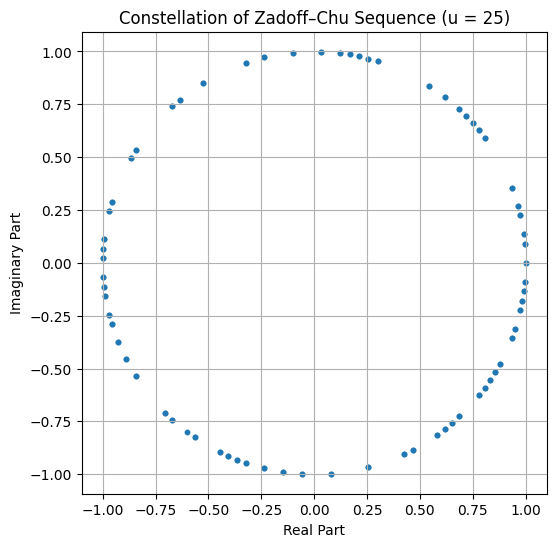

In [7]:
# --------------------------------------------------------
# Part 5.2 - Question 2: Four Zadoff-Chu Sequences
# --------------------------------------------------------

def generate_zadoff_chu(N, u):
    """
    Generate a Zadoff–Chu sequence.

    Parameters:
        N (int): Sequence length (preferably a prime number)
        u (int): Root index of the sequence

    Returns:
        seq (np.array): Generated complex sequence
    """
    n = np.arange(N)

    # Standard formula for odd-length sequences (as used in LTE)
    seq = np.exp(-1j * np.pi * u * n * (n + 1) / N)

    return seq


# --- Parameter Configuration ---
N_ZC = 139  # Sequence length (a commonly used prime number in LTE)

# Select roots
root_1 = 25
root_2 = 29  # A different root from the first one


# --- Generate the 4 Required Sequences ---

# 1. Generate two sequences with completely identical parameters (for autocorrelation test)
seq_A = generate_zadoff_chu(N_ZC, root_1)
seq_B = generate_zadoff_chu(N_ZC, root_1)  # Exactly identical to seq_A

# 2. Generate two sequences with different roots (for cross-correlation test)
# Note: seq_C is the same as seq_A, while seq_D has a different root.
seq_C = generate_zadoff_chu(N_ZC, root_1)
seq_D = generate_zadoff_chu(N_ZC, root_2)


# --- Display Information for the Report ---
print(f"Sequence Length (N_ZC): {N_ZC}")
print(f"Sequence A (Root = {root_1}) generated.")
print(f"Sequence B (Root = {root_1}) generated. (Identical to A)")
print(f"Sequence D (Root = {root_2}) generated. (Different root)")


# --- Plot Constellation to Verify Constant Amplitude Property ---
plt.figure(figsize=(6, 6))
plt.scatter(seq_A.real, seq_A.imag, marker='o', s=10)
plt.title(f"Constellation of Zadoff–Chu Sequence (u = {root_1})")
plt.xlabel("Real Part")
plt.ylabel("Imaginary Part")
plt.grid(True)
plt.axis('equal')  # Ensures the circle appears correctly
plt.show()


### Question 3 :
For each case:

- Plot the autocorrelation

- Plot the cross-correlation

Analyze the results and explain the differences in behavior between similar (identical-parameter) and different sequences.

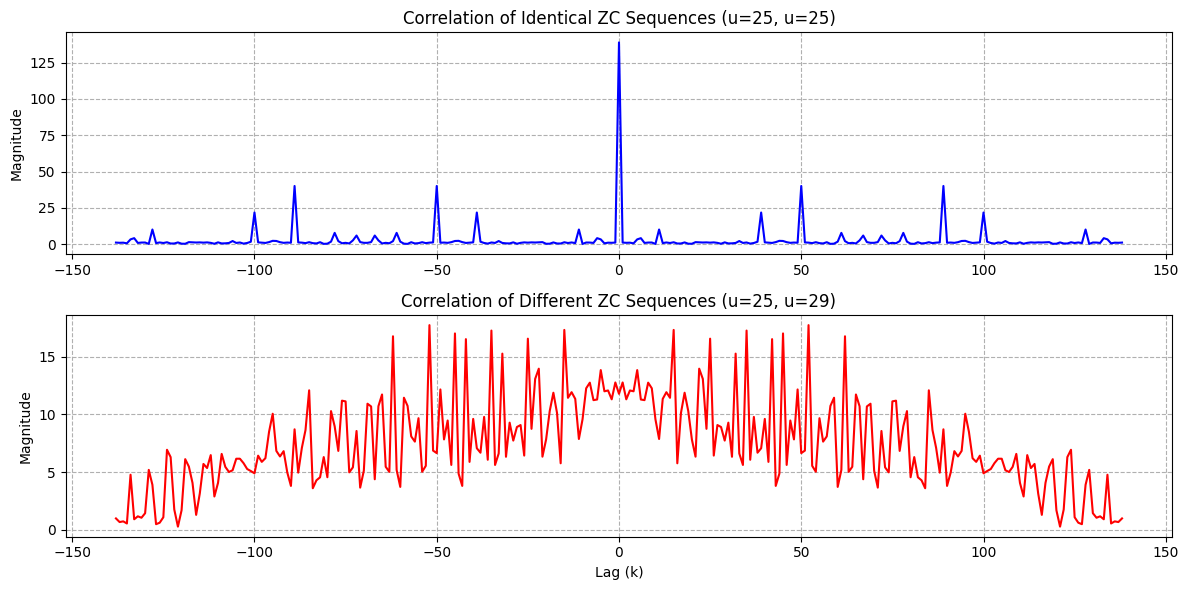

In [ ]:
# ------------------------------------------------------------
# Part 5.2 - Question 3: Autocorrelation & Crosscorrelation
# ------------------------------------------------------------

# 1. Compute correlation for identical sequences (Auto-correlation)
corr_similar, lags_similar = cross_correlation(seq_A, seq_A)

# 2. Compute correlation for different sequences (Cross-correlation)
corr_different, lags_different = cross_correlation(seq_A, seq_D)

# --- Plotting the results ---
plt.figure(figsize=(12, 6))

# First plot: Identical sequences
plt.subplot(2, 1, 1)
plt.plot(lags_similar, np.abs(corr_similar), color='blue', linewidth=1.5)
plt.title('Correlation of Identical ZC Sequences (u=25, u=25)')
plt.ylabel('Magnitude')
plt.grid(True, linestyle='--')

# Second plot: Different sequences
plt.subplot(2, 1, 2)
plt.plot(lags_different, np.abs(corr_different), color='red', linewidth=1.5)
plt.title('Correlation of Different ZC Sequences (u=25, u=29)')
plt.xlabel('Lag (k)')
plt.ylabel('Magnitude')
plt.grid(True, linestyle='--')

plt.tight_layout()
plt.show()


## Part 3 : MIB Detection and Random Access Procedure
### Question 1 :
Generate a random bit sequence of length 1000 bits and insert the MIB pattern at an arbitrary position within it.

In [12]:
# ------------------------------------------------------------
# Part 5.3 - Question 1: Bit Sequence with MIB pattern
# ------------------------------------------------------------

def generate_mib_scenario():
    """
    Generate a random bitstream and embed a known MIB pattern 
    at a random position.
    """
    # 1. Generate a random bitstream of length 1000
    total_bits = 1000
    random_bitstream = np.random.randint(0, 2, total_bits)
    
    # 2. Define a fixed MIB pattern (24 bits)
    # This pattern must be known to the receiver
    mib_pattern = np.array([
        1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1,
        1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1
    ])
    mib_length = len(mib_pattern)
    
    # 3. Select a random position to insert the MIB
    # Ensure the MIB does not exceed the 1000-bit length
    start_index = np.random.randint(0, total_bits - mib_length)
    
    # 4. Embed the MIB pattern into the main bitstream
    full_data = random_bitstream.copy()
    full_data[start_index : start_index + mib_length] = mib_pattern
    
    return full_data, mib_pattern, start_index


# Run the function and print results for reporting
full_bits, mib, actual_pos = generate_mib_scenario()

print(f"Total bitstream length: {len(full_bits)}")
print(f"MIB pattern (24 bits): {mib}")
print(f"Actual embedded position (Index): {actual_pos}")
print(f"Bits at embedded position:\n{full_bits[actual_pos : actual_pos + 24]}")


Total bitstream length: 1000
MIB pattern (24 bits): [1 1 0 1 1 0 0 1 0 1 0 1 1 1 0 0 0 1 1 0 1 0 1 1]
Actual embedded position (Index): 398
Bits at embedded position:
[1 1 0 1 1 0 0 1 0 1 0 1 1 1 0 0 0 1 1 0 1 0 1 1]


### Question 2 :
Modulate the signal using QPSK modulation and transmit it through a channel.

QPSK modulation completed.
Number of input bits: 1000
Number of output symbols: 500
Noise added with standard deviation 0.4.


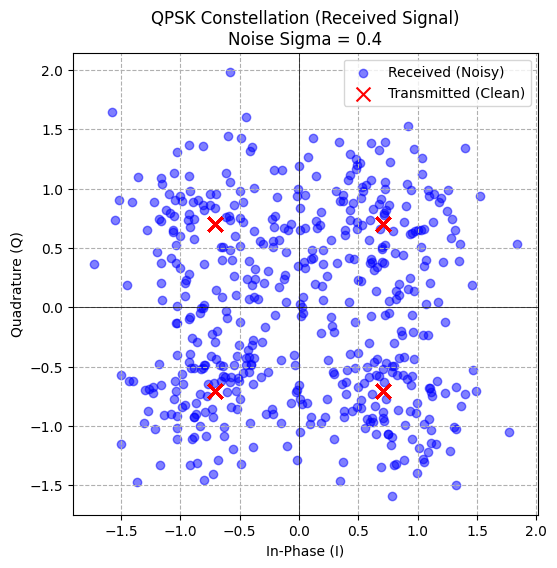

In [20]:
# ------------------------------------------------
# Part 5.3 - Question 2: QPSK Modulation
# ------------------------------------------------

# --- Helper Functions ---

def qpsk_modulator(bits):
    """
    Convert a bit array into QPSK symbols
    Input: bit array (length must be even)
    Output: array of complex symbols
    """
    # Check that the number of bits is even
    if len(bits) % 2 != 0:
        raise ValueError("Number of bits must be even for QPSK.")
    
    symbols = []
    # Process bits in pairs
    for i in range(0, len(bits), 2):
        b0 = bits[i]
        b1 = bits[i+1]
        
        # Map bits to phases (Gray mapping)
        # 00 -> 1+1j
        # 01 -> -1+1j
        # 11 -> -1-1j
        # 10 -> 1-1j
        # Normalize by 1/sqrt(2) for unit energy
        real = 1 if b0 == 0 else -1
        imag = 1 if b1 == 0 else -1
        
        symbol = (real + 1j * imag) / np.sqrt(2)
        symbols.append(symbol)
        
    return np.array(symbols)

def add_awgn_channel(signal, noise_power_db):
    """
    Add white Gaussian noise (AWGN) to a signal
    signal: complex input signal
    noise_power_db: noise power in dB
    """
    # Compute signal power
    sig_power = np.mean(np.abs(signal) ** 2)
    
    # Convert noise power from dB to linear scale
    # Here we assume a simple mapping from noise_power_db to sigma
    sigma = 10**(-noise_power_db / 20)
    
    # Generate complex Gaussian noise
    # Both real and imaginary parts are normal distributed
    noise = (np.random.randn(len(signal)) + 1j * np.random.randn(len(signal))) * sigma / np.sqrt(2)
    
    noisy_signal = signal + noise
    return noisy_signal

# --- Main Execution ---

# 1. QPSK Modulation
try:
    qpsk_symbols = qpsk_modulator(full_bits)
    print("QPSK modulation completed.")
    print(f"Number of input bits: {len(full_bits)}")
    print(f"Number of output symbols: {len(qpsk_symbols)}")
except ValueError as e:
    print(e)

# 2. Pass through channel (add noise)
# Here we assume a fixed noise sigma (e.g., 0.4) for visualization
sigma_noise = 0.4
noise = (np.random.randn(len(qpsk_symbols)) + 1j * np.random.randn(len(qpsk_symbols))) * sigma_noise
received_signal = qpsk_symbols + noise

print(f"Noise added with standard deviation {sigma_noise}.")

# --- Plot Constellation Diagram ---
plt.figure(figsize=(6, 6))
plt.scatter(received_signal.real, received_signal.imag, color='blue', alpha=0.5, label='Received (Noisy)')
plt.scatter(qpsk_symbols.real, qpsk_symbols.imag, color='red', marker='x', s=100, label='Transmitted (Clean)')
plt.title(f'QPSK Constellation (Received Signal)\nNoise Sigma = {sigma_noise}')
plt.xlabel('In-Phase (I)')
plt.ylabel('Quadrature (Q)')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--')
plt.legend()
plt.axis('equal')
plt.show()


### Question 3 :
Using correlation, detect the position of the MIB pattern in the received signal.

--- MIB Detection Results ---
Maximum correlation value: 10.84
Detected position (Symbol index): 199
Detected position (Bit index): 398
Ground truth position: 398
Detection error: 0 bits
>> Status: Successful detection


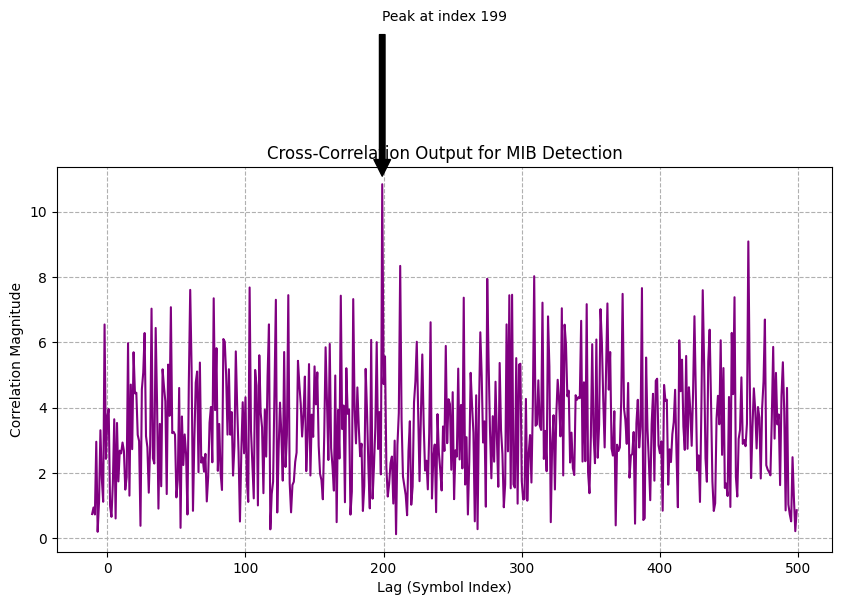

In [22]:
# ---------------------------------------------------
# Part 5.3 - Question 3: Detecting position of MIB
# ---------------------------------------------------

def detect_mib_position(received_signal, mib_bits, known_start_bit_index=None):
    """
    Detect the position of the MIB in the received signal
    """
    # 1. Convert MIB bit pattern to QPSK symbols (template creation)
    mib_symbols = qpsk_modulator(mib_bits)
    
    # 2. Compute cross-correlation between received signal and MIB template
    # Note: received_signal is long, mib_symbols is shorter
    correlation, lags = cross_correlation(received_signal, mib_symbols)
    
    # 3. Find the index of the maximum peak in the correlation output
    peak_idx = np.argmax(np.abs(correlation))
    detected_lag = lags[peak_idx]
    
    # 4. Convert symbol index to bit index
    # Each QPSK symbol represents 2 bits
    detected_symbol_index = detected_lag
    detected_bit_index = detected_symbol_index * 2
    
    # 5. Report results
    print(f"--- MIB Detection Results ---")
    print(f"Maximum correlation value: {np.abs(correlation[peak_idx]):.2f}")
    print(f"Detected position (Symbol index): {detected_symbol_index}")
    print(f"Detected position (Bit index): {detected_bit_index}")
    
    if known_start_bit_index is not None:
        print(f"Ground truth position: {known_start_bit_index}")
        error = known_start_bit_index - detected_bit_index
        print(f"Detection error: {error} bits")
        if error == 0:
            print(">> Status: Successful detection")
        else:
            print(">> Status: Detection error")
            
    return correlation, lags, detected_symbol_index

# --- Run the detection function ---
# actual_pos is the variable stored earlier during random generation in Section 3.5.1
corr_result, lag_axis, detected_sym = detect_mib_position(received_signal, mib, actual_pos)

# --- Plot cross-correlation for reporting ---
plt.figure(figsize=(10, 5))
plt.plot(lag_axis, np.abs(corr_result), color='purple')
plt.title('Cross-Correlation Output for MIB Detection')
plt.xlabel('Lag (Symbol Index)')
plt.ylabel('Correlation Magnitude')
plt.grid(True, linestyle='--')

# Mark the peak point
peak_val = np.max(np.abs(corr_result))
plt.annotate(f'Peak at index {detected_sym}', 
             xy=(detected_sym, peak_val), 
             xytext=(detected_sym, peak_val + 5),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.show()


### Question 4 :
After successful detection, the UE (User Equipment) randomly selects one of the 64 available Zadoff–Chu sequences as a RACH preamble and transmits it.

In [31]:
# ----------------------------------------------
# Part 5.3 - Question 4: UE Function
# ----------------------------------------------
def ue_send_rach_preamble(N_ZC=139):
    """
    Simulate UE behavior in randomly selecting and sending a RACH preamble
    """
    # 1. Define the search space (64 sequences available per cell)
    # In reality, these roots are predefined by the standard
    available_roots = np.arange(1, 65) 
    
    # 2. UE randomly selects one of the 64 sequences
    selected_root_idx = np.random.randint(0, 64)
    selected_root = available_roots[selected_root_idx]
    
    # 3. Generate Zadoff-Chu sequence based on the selected root
    # Using the generate_zadoff_chu function from Section 5.2
    n = np.arange(N_ZC)
    transmitted_preamble = np.exp(-1j * np.pi * selected_root * n * (n + 1) / N_ZC)
    
    print(f"--- UE RACH Transmission Process ---")
    print(f"Total number of codes available in the cell: 64")
    print(f"Randomly selected code index by UE: {selected_root_idx}")
    print(f"Corresponding root for the selected code: {selected_root}")
    
    return transmitted_preamble, selected_root

# --- Run the simulation ---
rach_signal, sent_root = ue_send_rach_preamble()


--- UE RACH Transmission Process ---
Total number of codes available in the cell: 64
Randomly selected code index by UE: 55
Corresponding root for the selected code: 56


### Question 5 :
At the receiver:

- Detect the received ZC signal.

- Represent the detected sequence index as a 6-bit number (since 64 sequences require 6 bits).

In [36]:
# -----------------------------------------------------------
# Part 5.3 - Question 5: Representing the Detected Sequence
# -----------------------------------------------------------
def gnb_receiver_detection(received_rach_signal, n_zc=139):
    """
    Simulate the base station receiver detecting the RACH preamble
    """
    max_corr = -1
    detected_index = -1
    
    # 1. Create a correlation bank for all 64 possible sequences
    for i in range(1, 65):  # Roots 1 to 64
        # Generate reference sequence for comparison
        n = np.arange(n_zc)
        reference_seq = np.exp(-1j * np.pi * i * n * (n + 1) / n_zc)
        
        # Compute correlation (only at zero lag, assuming synchronized scenario)
        # For higher accuracy in noisy environments, one could use cross_correlation
        correlation = np.abs(np.vdot(reference_seq, received_rach_signal))
        
        if correlation > max_corr:
            max_corr = correlation
            detected_index = i - 1  # Convert to 0-63 range
            
    # 2. Convert the detected sequence index to a 6-bit number
    six_bit_id = format(detected_index, '06b')
    
    return detected_index, six_bit_id

# --- Run the final simulation ---

# Add noise to the RACH signal before reaching the receiver
sigma_noise = 0.5
noisy_rach = rach_signal + (np.random.randn(len(rach_signal)) + 1j * np.random.randn(len(rach_signal))) * sigma_noise

# Detection at the gNB
detected_idx, bit_id = gnb_receiver_detection(noisy_rach)

print(f"--- Final gNB Receiver Output  ---")
print(f"Detected index at receiver: {detected_idx}")
print(f"Actual code sent by UE: {sent_root - 1}")  # For comparison (Root - 1)
print(f"Final digital output (6-bit ID): {bit_id}")

if detected_idx == (sent_root - 1):
    print("Result: 100% successful detection in noisy environment!")
else:
    print("Result: Detection error (due to high noise)")


--- Final gNB Receiver Output  ---
Detected index at receiver: 55
Actual code sent by UE: 55
Final digital output (6-bit ID): 110111
Result: 100% successful detection in noisy environment!


### Question 6 :
If the detected sequence matches the transmitted sequence, display the message:

“Attach Completed”

In [33]:
# ----------------------------------------------
# Part 5.3 - Question 6: ATTACH COMPLETE !
# ----------------------------------------------
def verify_attachment(sent_root, detected_index):
    """
    Check the correctness of the detected sequence and report attach status
    """
    # Note: In the previous code, sent_root is the actual root (1-64) 
    # and detected_index is the detected index (0-63).
    # For comparison, convert root to index
    actual_index = sent_root - 1
    
    print(f"--- Final Attach Validation ---")
    print(f"UE sent ID: {actual_index}")
    print(f"Network detected ID: {detected_index}")
    
    # Final comparison
    if detected_index == actual_index:
        print("\n***************************")
        print("* Attach Completed        *")
        print("***************************")
        return True
    else:
        print("\n---------------------------")
        print("-      Attach Failed      -")
        print("---------------------------")
        return False

# Run the final step
is_success = verify_attachment(sent_root, detected_idx)


--- Final Attach Validation ---
UE sent ID: 55
Network detected ID: 55

***************************
* Attach Completed        *
***************************


### Question 7 :
Finally, plot the following:

- The modulated MIB signal

- The transmitted Zadoff–Chu signal

- The correlation output at the receiver

- The modulated 6-bit signal

Then analyze the entire RACH procedure schematically and explain the overall process.

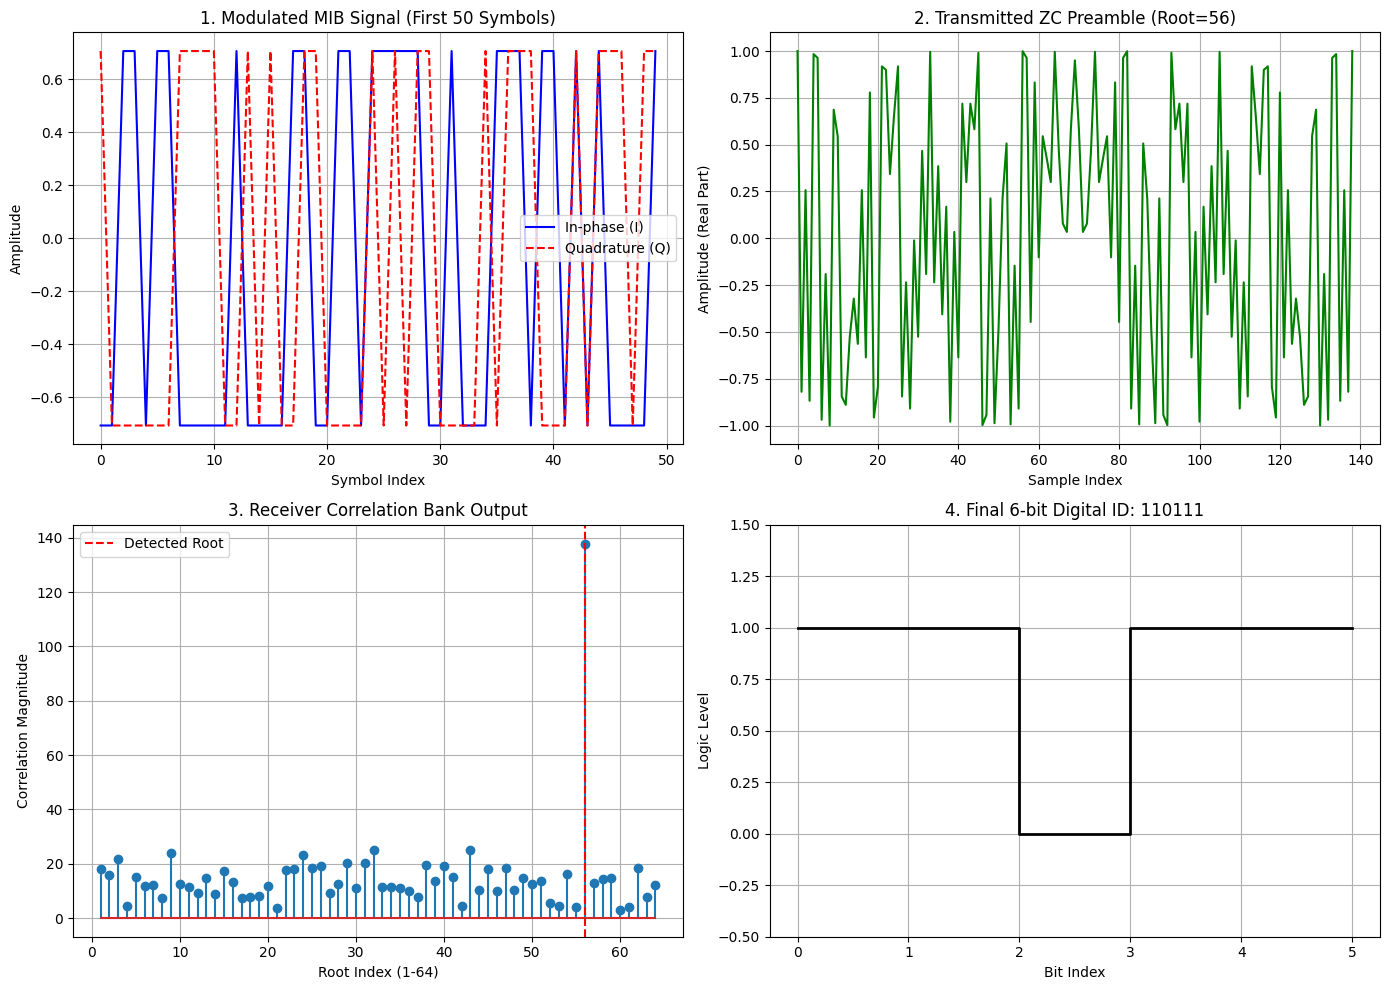

In [ ]:
# ----------------------------------------------
# Part 5.3 - Question 7: Plotting and Analyzing
# ----------------------------------------------

plt.figure(figsize=(14, 10))
# 1. Modulated MIB signal (real and imaginary parts)
plt.subplot(2, 2, 1)
plt.plot(qpsk_symbols.real[:50], 'b-', label='In-phase (I)')
plt.plot(qpsk_symbols.imag[:50], 'r--', label='Quadrature (Q)')
plt.title('1. Modulated MIB Signal (First 50 Symbols)')
plt.xlabel('Symbol Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)

# 2. Transmitted Zadoff-Chu Preamble (time domain)
plt.subplot(2, 2, 2)
plt.plot(rach_signal.real, 'g-')
plt.title(f'2. Transmitted ZC Preamble (Root={sent_root})')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude (Real Part)')
plt.grid(True)

# 3. Receiver correlation bank output (RACH root detection)
# Here we compute and plot correlation for all 64 roots
correlation_bank = []
for i in range(1, 65):
    ref = np.exp(-1j * np.pi * i * np.arange(139) * (np.arange(139) + 1) / 139)
    correlation_bank.append(np.abs(np.vdot(ref, noisy_rach)))

plt.subplot(2, 2, 3)
plt.stem(range(1, 65), correlation_bank)
plt.axvline(sent_root, color='r', linestyle='--', label='Detected Root')
plt.title('3. Receiver Correlation Bank Output')
plt.xlabel('Root Index (1-64)')
plt.ylabel('Correlation Magnitude')
plt.legend()
plt.grid(True)

# 4. Final 6-bit digital output (logic display)
plt.subplot(2, 2, 4)
bit_array = np.array([int(b) for b in bit_id])
plt.step(range(len(bit_array)), bit_array, where='post', color='black', linewidth=2)
plt.ylim(-0.5, 1.5)
plt.title(f'4. Final 6-bit Digital ID: {bit_id}')
plt.xlabel('Bit Index')
plt.ylabel('Logic Level')
plt.grid(True)

plt.tight_layout()
plt.show()
